# Figure 4a
The directed cycle with $N=10$. The ring marks the initial mutant at vertex 1. The vertex shades are the location colors of panels b to d.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

from fixloc import style as S

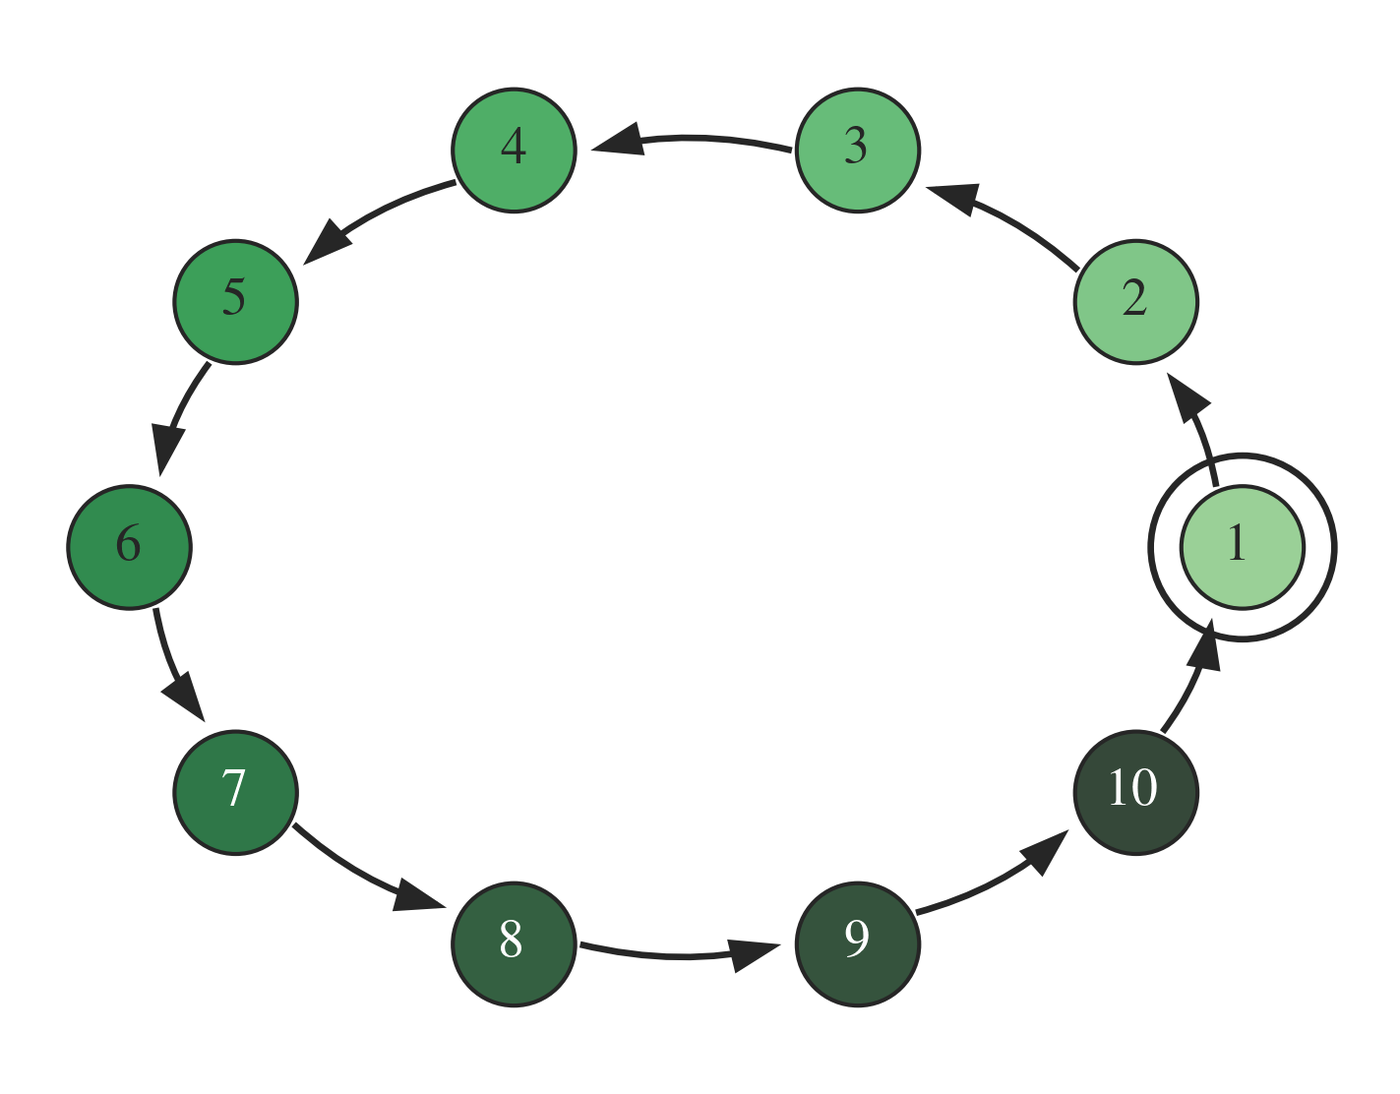

In [2]:
H_IN = 6.95
top = 2.62 / H_IN
y0 = 1 - top
fig = plt.figure(figsize=(7.0, H_IN))
ax = fig.add_axes([0.012, y0 + 0.02, 0.33, top - 0.045])
ax.set_aspect('equal')
ax.set_axis_off()
n, R = 10, 0.11
th = 2 * np.pi * np.arange(n) / n
pos = np.c_[np.cos(th), 0.75 * np.sin(th)]
for k in range(n):
  p, q = pos[k], pos[(k + 1) % n]
  d = (q - p) / np.linalg.norm(q - p)
  ax.add_patch(
    FancyArrowPatch(p + d * R * 1.08, q - d * R * 1.25, arrowstyle=S.HEAD, mutation_scale=7.5, lw=0.8, color=S.INK,
                    connectionstyle='arc3,rad=0.12', shrinkA=0, shrinkB=0, joinstyle='miter', capstyle='butt', zorder=2)
  )
for k in range(n):
  ax.add_patch(Circle(pos[k], R, facecolor=S.CM_CYC(k / (n - 1)), edgecolor=S.INK, lw=0.5, zorder=3))
  ax.text(*pos[k], r'$%d$' % (k + 1), ha='center', va='center', fontsize=6.5, color='white' if k >= 6 else S.INK, zorder=4)
ax.add_patch(Circle(pos[0], 1.5 * R, facecolor='none', edgecolor=S.INK, lw=0.8, zorder=3))  # the initial mutant
ax.set_xlim(-1.2, 1.25)
ax.set_ylim(-0.95, 0.95)
S.save_panel(fig, 'a')